# Assignment 1

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [2]:
import requests
from bs4 import BeautifulSoup

def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(
        url,
        headers={'User-Agent': 'Mozilla/5.0'},
        timeout=10
    )
    response.raise_for_status()

    soup = BeautifulSoup(response.text, 'html.parser')
    text = soup.get_text(separator="\n", strip=True)

    return text

print(parse_web_page('https://en.wikipedia.org/wiki/Web_scraping')[:255])

Web scraping - Wikipedia
Jump to content
Main menu
Main menu
move to sidebar
hide
Navigation
Main page
Contents
Current events
Random article
About Wikipedia
Contact us
Contribute
Help
Learn to edit
Community portal
Recent changes
Upload file
Special page


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [5]:
import requests
import json

def parse_api(api_url):
    """
    Fetch the data of the given API endpoint and save it to result.json.

    Args:
        api_url (str): The URL of the API endpoint.

    Returns:
        None.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(api_url, timeout=10)
    response.raise_for_status()

    data = response.json()

    with open("result.json", "w", encoding="utf-8") as file:
        json.dump(data, file, indent=4)
    return None 

"""
    Replace the following api with api you wish to parse for this assignemnt.
    You can use https://free-apis.github.io/#/ or any other available api endpoint you like.
"""
parse_api('https://api.github.com/')

## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [6]:
import json
from datetime import datetime

def parse_json(date):
    """
    Parse the data from weather.json file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    requested_date = datetime.strptime(
        target_date, "%Y-%m-%d"
    ).date().isoformat()

    with open("resources/weather.json", "r", encoding="utf-8") as file:
        weather_data = json.load(file)

    return [
        item for item in weather_data["daily"]
        if item["date"] == requested_date
    ]

    
target_date = '2024-8-19'
print(parse_json(target_date))

[{'date': '2024-08-19', 'max_temperature': 30.0, 'min_temperature': 21.0, 'precipitation': 5.0, 'wind_speed': 10.0, 'humidity': 70, 'weather_description': 'Light rain'}]


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [10]:
import csv
from datetime import datetime

def parse_csv(target_date):
    """
    Parse the data from weather.csv file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    requested_date = datetime.strptime(
        target_date, "%Y-%m-%d"
    ).date()

    with open(
        "resources/weather.csv",
        "r",
        encoding="utf-8",
        newline=""
    ) as file:
        rows = csv.DictReader(file)

        return [
            row for row in rows
            if datetime.strptime(
                row["CET"], "%Y-%m-%d"
            ).date() == requested_date
        ]
    
target_date = '1997-5-22'
print(parse_csv(target_date))

[{'CET': '1997-5-22', 'Max TemperatureC': '25', 'Mean TemperatureC': '18', 'Min TemperatureC': '10', 'Dew PointC': '11', 'MeanDew PointC': '8', 'Min DewpointC': '6', 'Max Humidity': '88', ' Mean Humidity': '54', ' Min Humidity': '34', ' Max Sea Level PressurehPa': '1017', ' Mean Sea Level PressurehPa': '1015', ' Min Sea Level PressurehPa': '1012', ' Max VisibilityKm': '10', ' Mean VisibilityKm': '10', ' Min VisibilitykM': '10', ' Max Wind SpeedKm/h': '11', ' Mean Wind SpeedKm/h': '3', ' Max Gust SpeedKm/h': '', 'Precipitationmm': '0.00', ' CloudCover': '3', ' Events': '', 'WindDirDegrees': '277'}]


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

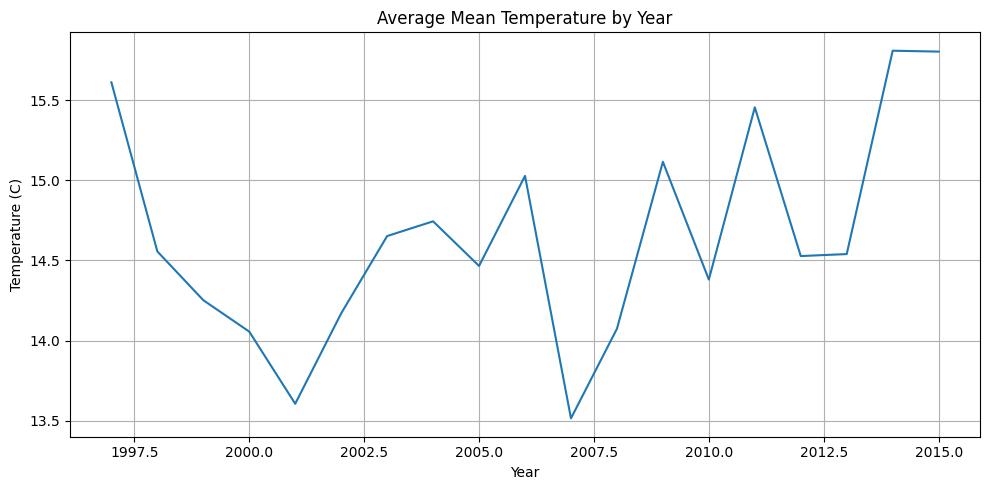

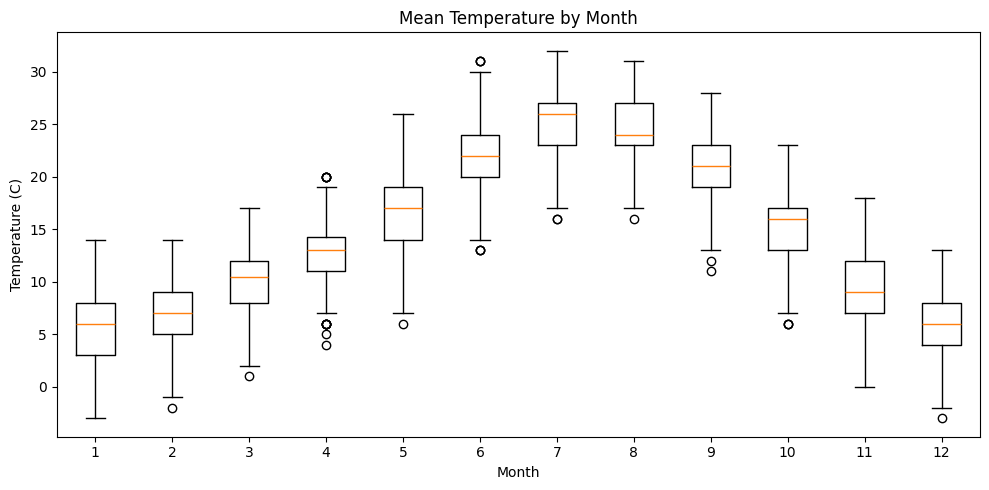

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

def visualize_data():
    """
    Parse the data from weather.csv file and visualize it using Matplotlib. Use more then one visualization.
    Save the results in the repository.

    Args:
        None: None.

    Returns:
        None: None.
    """
    data = pd.read_csv("resources/weather.csv")
    data["CET"] = pd.to_datetime(data["CET"])

    yearly_temperature = (
        data.groupby(data["CET"].dt.year)["Mean TemperatureC"].mean()
    )

    plt.figure(figsize=(10, 5))
    plt.plot(yearly_temperature.index, yearly_temperature.values)
    plt.title("Average Mean Temperature by Year")
    plt.xlabel("Year")
    plt.ylabel("Temperature (C)")
    plt.grid()
    plt.tight_layout()
    plt.savefig("weather_temperature_by_year.png")
    plt.show()

    monthly_temperature = [
        data.loc[
            data["CET"].dt.month == month,
            "Mean TemperatureC"
        ].dropna()
        for month in range(1, 13)
    ]

    plt.figure(figsize=(10, 5))
    plt.boxplot(monthly_temperature, tick_labels=range(1, 13))
    plt.title("Mean Temperature by Month")
    plt.xlabel("Month")
    plt.ylabel("Temperature (C)")
    plt.tight_layout()
    plt.savefig("weather_temperature_by_month.png")
    plt.show()

visualize_data()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by 
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

Missing values before imputation:
gender                          0
race/ethnicity                  0
parental level of education     0
lunch                          25
test preparation course         0
math score                      0
reading score                   0
writing score                   0
dtype: int64

Missing values after KNN imputation:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


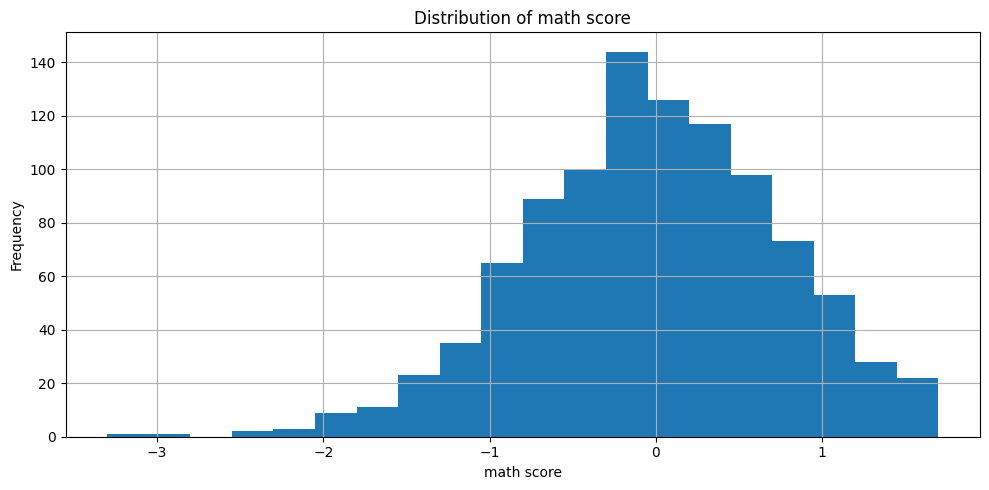

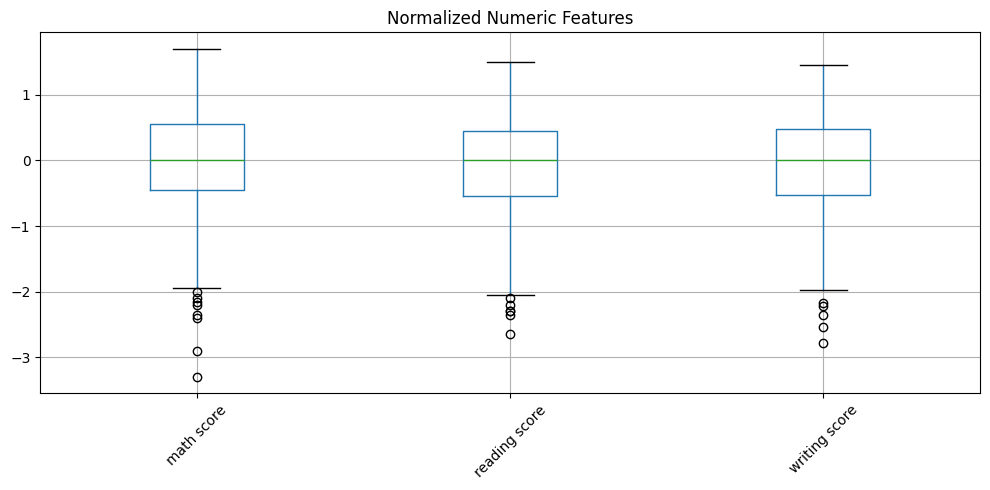

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import kagglehub

from kagglehub import KaggleDatasetAdapter
from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler


def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """

    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def impute_data(df, method="knn"):
    """
    Parse the data from file and impute missing values using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with imputed values.
    """
    result = df.copy()

    numeric_columns = result.select_dtypes(
        include="number"
    ).columns

    categorical_columns = result.select_dtypes(
            exclude="number"
    ).columns

    if method == "mean":
        result[numeric_columns] = result[numeric_columns].fillna(
            result[numeric_columns].mean()
        )

    elif method == "median":
        result[numeric_columns] = result[numeric_columns].fillna(
            result[numeric_columns].median()
        )

    elif method == "mode":
        for column in numeric_columns:
            result[column] = result[column].fillna(
                result[column].mode().iloc[0]
            )

    elif method == "knn":
        imputer = KNNImputer(n_neighbors=5)
        result[numeric_columns] = imputer.fit_transform(
            result[numeric_columns]
        )

    else:
        raise ValueError(
            "method must be mean, median, mode, or knn"
        )

    for column in categorical_columns:
        if result[column].isna().any():
            result[column] = result[column].fillna(
                result[column].mode().iloc[0]
            )

    return result



def normalize_data(df):
    """
    Normalize the data using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with normalized values.
    """
    result = df.copy()

    numeric_columns = result.select_dtypes(
        include="number"
    ).columns

    scaler = RobustScaler()
    result[numeric_columns] = scaler.fit_transform(
        result[numeric_columns]
    )

    return result

def visualize_data(df):
    """
    Visualize the data using Matplotlib. Use more then one visualization. 
    Save the results in the repository.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        None: None.
    """
    numeric_columns = df.select_dtypes(
        include="number"
    ).columns

    if len(numeric_columns) == 0:
        raise ValueError("The dataset has no numeric columns.")

    first_column = numeric_columns[0]

    plt.figure(figsize=(10, 5))
    df[first_column].hist(bins=20)
    plt.title(f"Distribution of {first_column}")
    plt.xlabel(first_column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig("imputed_data_distribution.png")
    plt.show()

    plt.figure(figsize=(10, 5))
    df[numeric_columns].boxplot()
    plt.title("Normalized Numeric Features")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig("normalized_data_boxplot.png")
    plt.show()


df = load_dataset(
    "ilayaraja07/data-cleaning-feature-imputation",
    "Students_Performance_knn.csv"
)

print("Missing values before imputation:")
print(df.isna().sum())

mean_data = impute_data(df, method="mean")
median_data = impute_data(df, method="median")
mode_data = impute_data(df, method="mode")
knn_data = impute_data(df, method="knn")

df = normalize_data(knn_data)

print("\nMissing values after KNN imputation:")
print(df.isna().sum())

visualize_data(df)